In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, TreeSearch, MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination
from pgmpy.independencies import IndependenceAssertion
import networkx as nx
from pgmpy.estimators import BayesianEstimator
from pgmpy.estimators import ExpectationMaximization

import copy

TODO: Explain what we did in preprocess
TODO: introduce what we're doing here

In [16]:
df.head()

,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,BPM,Anxiety,Depression,Insomnia,OCD
0,3.0,Yes,Yes,Yes,Latin,Yes,156.0,1,0,0,0
1,1.5,Yes,No,No,Rock,Yes,119.0,2,1,1,0
2,4.0,No,No,No,Video game music,No,132.0,2,2,3,0
3,2.5,Yes,No,Yes,Jazz,Yes,84.0,3,2,1,0
4,4.0,Yes,No,No,R&B,Yes,107.0,2,1,2,1


In [17]:
df.describe()

,Hours per day,BPM
count,609.000000,609.000000
mean,3.497865,123.929392
std,2.504096,32.072440
min,0.000000,40.000000
25%,2.000000,100.000000
50%,3.000000,120.000000
75%,5.000000,144.000000
max,12.000000,220.000000


Our goal in this project is to investigate the causal relation between music taste and mental illness and experiment with different ways of modeling it. This is acheived by a three step process by:

1. Determining the direction of the causal relation by infering causality (different from establishing causality)
3. Learn a network with pgmpy and compare it to our results
2. Investigating different setups using estimation approaches and latent variables (+ BIC score evaluation of the networks)

In [18]:
personal_causes = [
    ('Instrumentalist', 'Composer'),
    ('Instrumentalist', 'Hours per day'),
    ('Instrumentalist', 'Fav genre'),
    ('Composer', 'Hours per day'),
    ('Composer', 'Fav genre'),
    ('While working', 'Hours per day'),
]

genre_causes = [
    ('Fav genre', 'BPM')
]

mental_health_causes_taste = [
    ('Anxiety', 'Fav genre'),
    ('Anxiety', 'BPM'),
    ('Anxiety', 'Hours per day'),
    ('Anxiety', 'Exploratory'),
    ('Depression', 'Fav genre'),
    ('Depression', 'BPM'),
    ('Depression', 'Hours per day'),
    ('Depression', 'Exploratory'),
    ('Insomnia', 'Fav genre'),
    ('Insomnia', 'BPM'),
    ('Insomnia', 'Hours per day'),
    ('Insomnia', 'Exploratory'),
    ('OCD', 'Fav genre'),
    ('OCD', 'BPM'),
    ('OCD', 'Hours per day'),
    ('OCD', 'Exploratory')
] + personal_causes + genre_causes


taste_causes_mental_health = [
    ('Fav genre', 'Anxiety'),
    ('BPM', 'Anxiety'),
    ('Hours per day', 'Anxiety'),
    ('Exploratory', 'Anxiety'),
    ('Fav genre', 'Depression'),
    ('BPM', 'Depression'),
    ('Hours per day', 'Depression'),
    ('Exploratory', 'Depression'),
    ('Fav genre', 'Insomnia'),
    ('BPM', 'Insomnia'),
    ('Hours per day', 'Insomnia'),
    ('Exploratory', 'Insomnia'),
    ('Fav genre', 'OCD'),
    ('BPM', 'OCD'),
    ('Hours per day', 'OCD'),
    ('Exploratory', 'OCD')
] + personal_causes + genre_causes

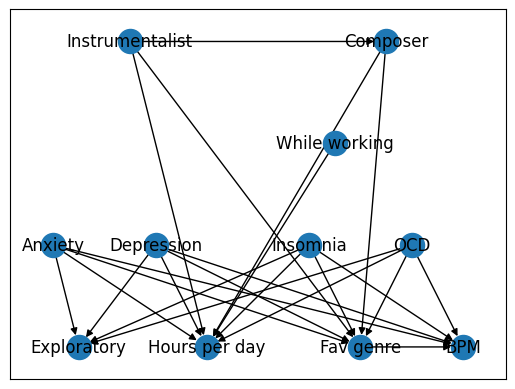

In [19]:
BN_mhct = DiscreteBayesianNetwork(mental_health_causes_taste)

G = nx.DiGraph()
G.add_edges_from(BN_mhct.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.5],
        'Anxiety': [0.1, -2],
        'Depression': [0.3, -2],
        'Insomnia': [0.6, -2],
        'OCD': [0.8, -2],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos=pos)


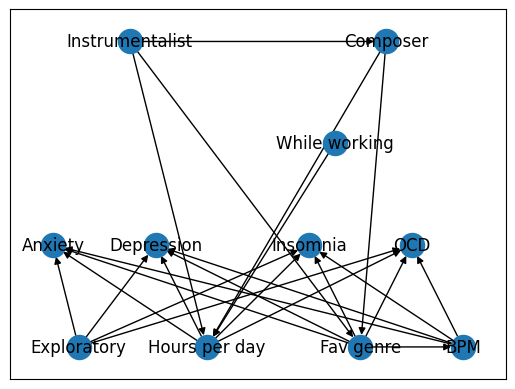

In [20]:
BN_tcmh = DiscreteBayesianNetwork(taste_causes_mental_health)

G = nx.DiGraph()
G.add_edges_from(BN_tcmh.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.5],
        'Anxiety': [0.1, -2],
        'Depression': [0.3, -2],
        'Insomnia': [0.6, -2],
        'OCD': [0.8, -2],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos=pos)

In [21]:
mhct_copy = copy.deepcopy(BN_mhct)
tcmh_copy = copy.deepcopy(BN_tcmh)

mhct_estimator = BayesianEstimator(mhct_copy, df)
tcmh_estimator = BayesianEstimator(tcmh_copy, df)

mhct_estimation = mhct_estimator.get_parameters()
tcmh_estimation = tcmh_estimator.get_parameters()

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}


In [22]:
import numpy as np
import pandas as pd
from pgmpy.estimators import BIC, BDeu, K2, AIC, BDs

# Number of bootstrap resamples
n_bootstrap = 50
random_state = 42
rng = np.random.default_rng(random_state)

# Containers for bootstrap scores
bootstrap_scores = {
    'BIC': {'MHCT': [], 'TCMH': []},
    'BDeu': {'MHCT': [], 'TCMH': []},
    'K2': {'MHCT': [], 'TCMH': []},
    'AIC': {'MHCT': [], 'TCMH': []},
    'BDs': {'MHCT': [], 'TCMH': []}
}

# Perform bootstrapping
for i in range(n_bootstrap):
    sample_idx = rng.choice(df.index, size=len(df), replace=True)
    df_sample = df.iloc[sample_idx].reset_index(drop=True)

    # Compute all scores for this bootstrap sample
    bic_mhct = BIC(df_sample).score(mhct_copy)
    bic_tcmh = BIC(df_sample).score(tcmh_copy)

    bdeu_mhct = BDeu(df_sample).score(mhct_copy)
    bdeu_tcmh = BDeu(df_sample).score(tcmh_copy)

    k2_mhct = K2(df_sample).score(mhct_copy)
    k2_tcmh = K2(df_sample).score(tcmh_copy)

    aic_mhct = AIC(df_sample).score(mhct_copy)
    aic_tcmh = AIC(df_sample).score(tcmh_copy)

    bds_mhct = BDs(df_sample).score(mhct_copy)
    bds_tcmh = BDs(df_sample).score(tcmh_copy)

    # Store results
    bootstrap_scores['BIC']['MHCT'].append(bic_mhct)
    bootstrap_scores['BIC']['TCMH'].append(bic_tcmh)

    bootstrap_scores['BDeu']['MHCT'].append(bdeu_mhct)
    bootstrap_scores['BDeu']['TCMH'].append(bdeu_tcmh)

    bootstrap_scores['K2']['MHCT'].append(k2_mhct)
    bootstrap_scores['K2']['TCMH'].append(k2_tcmh)

    bootstrap_scores['AIC']['MHCT'].append(aic_mhct)
    bootstrap_scores['AIC']['TCMH'].append(aic_tcmh)

    bootstrap_scores['BDs']['MHCT'].append(bds_mhct)
    bootstrap_scores['BDs']['TCMH'].append(bds_tcmh)

# Compute means and standard deviations
rows = []
for score_type, values in bootstrap_scores.items():
    mhct_mean = np.mean(values['MHCT'])
    tcmh_mean = np.mean(values['TCMH'])
    mhct_std = np.std(values['MHCT'])
    tcmh_std = np.std(values['TCMH'])
    better = 'MHCT' if mhct_mean > tcmh_mean else 'TCMH'
    rows.append({
        'Score Type': score_type,
        'MHCT (mean)': mhct_mean,
        'MHCT (std)': mhct_std,
        'TCMH (mean)': tcmh_mean,
        'TCMH (std)': tcmh_std,
        'Better Model': better
    })

# Create summary DataFrame
score_comparison = pd.DataFrame(rows)

score_comparison


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) in

,Score Type,MHCT (mean),MHCT (std),TCMH (mean),TCMH (std),Better Model
0,BIC,-815331.162893,28471.113042,-1.983783e+06,125293.636127,MHCT
1,BDeu,-10378.883088,125.787673,-9.539025e+03,87.365833,TCMH
2,K2,767647.605235,36107.051261,3.191926e+05,20969.637809,MHCT
3,AIC,-257844.100585,8883.172299,-6.228030e+05,39081.769768,MHCT
4,BDs,-20861.686308,165.716735,-8.978916e+05,56609.632279,MHCT


In [23]:
custom_priors = {
    "Anxiety": 5* np.array([[84, 10, 3, 3]]).T,
    "Depression": 5 *np.array([[81, 12, 4, 3]]).T,
    "Insomnia": 5 *np.array([[82, 10, 2, 6]]).T,
    "OCD": 5 * np.array([[97, 3]]).T
}

# Create the estimator
mhct_prior_copy = copy.deepcopy(mhct_copy)
mhct_prior_estimator = BayesianEstimator(mhct_copy, df)

# Fit with custom priors (applied only to the specified variables)
for node in mhct_prior_copy.nodes():
    if node in custom_priors:
      cpd = mhct_prior_estimator.estimate_cpd(
          node,
          prior_type="dirichlet",
          pseudo_counts=custom_priors[node]  # only for selected variables
      )
    else:
        # Default prior for other nodes
        cpd = mhct_prior_estimator.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10)
    mhct_prior_copy.add_cpds(cpd)

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}


In [24]:
print(mhct_prior_copy.get_cpds('Anxiety'))

+------------+----------+
| Anxiety(0) | 0.422904 |
+------------+----------+
| Anxiety(1) | 0.13165  |
+------------+----------+
| Anxiety(2) | 0.254283 |
+------------+----------+
| Anxiety(3) | 0.191163 |
+------------+----------+


In [25]:
import numpy as np
import pandas as pd
from pgmpy.estimators import BIC, BDeu, K2, AIC, BDs

# Number of bootstrap resamples
n_bootstrap = 50
random_state = 42
rng = np.random.default_rng(random_state)

# Containers for bootstrap scores
bootstrap_scores = {
    'BIC': {'MHCT': [], 'MHCT (with prior)': []},
    'BDeu': {'MHCT': [], 'MHCT (with prior)': []},
    'K2': {'MHCT': [], 'MHCT (with prior)': []},
    'AIC': {'MHCT': [], 'MHCT (with prior)': []},
    'BDs': {'MHCT': [], 'MHCT (with prior)': []}
}

# Perform bootstrapping
for i in range(n_bootstrap):
    sample_idx = rng.choice(df.index, size=len(df), replace=True)
    df_sample = df.iloc[sample_idx].reset_index(drop=True)

    # Compute all scores for this bootstrap sample
    bic_mhct = BIC(df_sample).score(mhct_copy)
    bic_mhct_prior = BIC(df_sample).score(mhct_prior_copy)

    bdeu_mhct = BDeu(df_sample).score(mhct_copy)
    bdeu_mhct_prior = BDeu(df_sample).score(mhct_prior_copy)

    k2_mhct = K2(df_sample).score(mhct_copy)
    k2_mhct_prior = K2(df_sample).score(mhct_prior_copy)

    aic_mhct = AIC(df_sample).score(mhct_copy)
    aic_mhct_prior = AIC(df_sample).score(mhct_prior_copy)

    bds_mhct = BDs(df_sample).score(mhct_copy)
    bds_mhct_prior = BDs(df_sample).score(mhct_prior_copy)

    # Store results
    bootstrap_scores['BIC']['MHCT'].append(bic_mhct)
    bootstrap_scores['BIC']['MHCT (with prior)'].append(bic_mhct_prior)

    bootstrap_scores['BDeu']['MHCT'].append(bdeu_mhct)
    bootstrap_scores['BDeu']['MHCT (with prior)'].append(bdeu_mhct_prior)

    bootstrap_scores['K2']['MHCT'].append(k2_mhct)
    bootstrap_scores['K2']['MHCT (with prior)'].append(k2_mhct_prior)

    bootstrap_scores['AIC']['MHCT'].append(aic_mhct)
    bootstrap_scores['AIC']['MHCT (with prior)'].append(aic_mhct_prior)

    bootstrap_scores['BDs']['MHCT'].append(bds_mhct)
    bootstrap_scores['BDs']['MHCT (with prior)'].append(bds_mhct_prior)

# Compute means and standard deviations
rows = []
for score_type, values in bootstrap_scores.items():
    mhct_mean = np.mean(values['MHCT'])
    mhct_prior_mean = np.mean(values['MHCT (with prior)'])
    mhct_std = np.std(values['MHCT'])
    mhct_prior_std = np.std(values['MHCT (with prior)'])
    better = 'MHCT' if mhct_mean > mhct_prior_mean else 'MHCT (with prior)'
    rows.append({
        'Score Type': score_type,
        'MHCT (mean)': mhct_mean,
        'MHCT (std)': mhct_std,
        'MHCT (with prior) (mean)': mhct_prior_mean,
        'MHCT (with prior) (std)': mhct_prior_std,
        'Better Model': better
    })

# Create summary DataFrame
score_comparison = pd.DataFrame(rows)

score_comparison

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Hours per day': 'N', 'While working': 'C', 'Instrumentalist': 'C', 'Composer': 'C', 'Fav genre': 'C', 'Exploratory': 'C', 'BPM': 'N', 'Anxiety': 'O', 'Depression': 'O', 'Insomnia': 'O', 'OCD': 'O'}
INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) in

,Score Type,MHCT (mean),MHCT (std),MHCT (with prior) (mean),MHCT (with prior) (std),Better Model
0,BIC,-815331.162893,28471.113042,-815331.162893,28471.113042,MHCT (with prior)
1,BDeu,-10378.883088,125.787673,-10378.883088,125.787673,MHCT (with prior)
2,K2,767647.605235,36107.051261,767647.605235,36107.051261,MHCT (with prior)
3,AIC,-257844.100585,8883.172299,-257844.100585,8883.172299,MHCT (with prior)
4,BDs,-20861.686308,165.716735,-20861.686308,165.716735,MHCT (with prior)


In [14]:
latent_edges = [
    ('Internalization', 'Depression'),
    ('Internalization', 'Anxiety'),
    ('Internalization', 'Insomnia'),
    ('Internalization', 'OCD')
]